# Benchmark Coverage Analysis

Three sections:
1. **MCP tool coverage** — which tools are tested, which are missing
2. **Benchmark composition** — tasks by category and by server
3. **Task browser** — searchable overview + per-task detail viewer

In [1]:
import json
import subprocess
import sys
from pathlib import Path
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from IPython.display import display, HTML

ROOT = Path("..")
TASKS_FILE  = ROOT / "data" / "tasks" / "benchmark_tasks.json"
SKILL_SCRIPT = Path.home() / ".claude/skills/eomcpevaluation/scripts/analyze_coverage.py"

CATEGORY_COLORS = {
    "Tool Grounding":       "#4c72b0",
    "Sequential Reasoning": "#dd8452",
    "Cross-agent Synthesis":"#55a868",
    "Scope Awareness":      "#c44e52",
}
SERVER_COLORS = {
    "eodashboard":      "#4c72b0",
    "gee-mcp":          "#55a868",
    "hybridrag":        "#dd8452",
    "moocs":            "#c44e52",
    "arxiv-mcp-server": "#8172b2",
    "gis-mcp":          "#64b5cd",
    "eve_retrieval":    "#ccb974",
}

print(f"Tasks file : {TASKS_FILE}")
print(f"Skill script: {SKILL_SCRIPT}")

Tasks file : ../data/tasks/benchmark_tasks.json
Skill script: /shared/home/rdercole/.claude/skills/eomcpevaluation/scripts/analyze_coverage.py


---
## 1 — MCP Tool Coverage

In [2]:
# Run the coverage analysis script and parse its JSON output
result = subprocess.run(
    [sys.executable, str(SKILL_SCRIPT), str(ROOT)],
    capture_output=True, text=True
)
if result.returncode != 0:
    print("STDERR:", result.stderr)
    raise RuntimeError("analyze_coverage.py failed")

analysis = json.loads(result.stdout)
tc  = analysis["task_coverage"]
mc  = analysis["mcp_tool_coverage"]

print(f"Files scanned : {[Path(f).name for f in tc['_files_scanned']]}")
print(f"Total tasks   : {tc['_total_tasks']}")

Files scanned : ['benchmark_tasks.json']
Total tasks   : 131


In [3]:
# Build coverage DataFrame: one row per (server, tool)
rows = []
for server, info in mc.items():
    if not info["tools"]:
        rows.append({
            "Server": server,
            "Source": info["source"],
            "Tool": "—",
            "Active tasks": 0,
            "Covered": False,
            "Categories": "(no tools registered)",
        })
        continue
    for tool, td in info["tools"].items():
        rows.append({
            "Server": server,
            "Source": info["source"],
            "Tool": tool,
            "Active tasks": td["active_task_count"],
            "Covered": td["covered"],
            "Categories": ", ".join(td["categories"]) if td["categories"] else "—",
        })

df_cov = pd.DataFrame(rows)

def _color_covered(val):
    return "background-color: #d4edda" if val else "background-color: #f8d7da"

def _color_count(val):
    if val == 0:   return "color: #721c24"
    if val < 3:    return "color: #856404"
    return "color: #155724"

styled = (
    df_cov.style
    .map(_color_covered, subset=["Covered"])
    .map(_color_count,   subset=["Active tasks"])
    .set_caption("MCP Tool Coverage — green = covered, red = missing")
    .set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "13px"), ("font-weight", "bold"), ("text-align", "left")]
    }])
    .hide(axis="index")
)
display(styled)

n_covered   = df_cov[df_cov["Tool"] != "—"]["Covered"].sum()
n_total     = (df_cov["Tool"] != "—").sum()
print(f"\nSummary: {n_covered}/{n_total} tools have at least one active task")
uncovered = df_cov[~df_cov["Covered"] & (df_cov["Tool"] != "—")][["Server", "Tool"]]
if len(uncovered):
    print("Uncovered tools:")
    print(uncovered.to_string(index=False))
else:
    print("All tools are covered.")

Server,Source,Tool,Active tasks,Covered,Categories
eodashboard,local,list_narratives,2,True,"Tool Grounding, Sequential Reasoning"
eodashboard,local,search_narratives,32,True,"Tool Grounding, Cross-agent Synthesis, Sequential Reasoning"
eodashboard,local,get_narrative_content,9,True,"Tool Grounding, Sequential Reasoning, Cross-agent Synthesis"
eodashboard,local,list_themes,2,True,Tool Grounding
eodashboard,local,get_narrative_indicators,18,True,"Tool Grounding, Cross-agent Synthesis, Sequential Reasoning"
eodashboard,local,search_collections,3,True,"Tool Grounding, Sequential Reasoning"
eodashboard,local,get_collection_items,11,True,"Cross-agent Synthesis, Sequential Reasoning"
eodashboard,local,find_narratives_for_indicator,2,True,Tool Grounding
gee-mcp,local,get_bbox,2,True,"Tool Grounding, Sequential Reasoning"
gee-mcp,local,download_satellite_image,32,True,"Sequential Reasoning, Cross-agent Synthesis, Tool Grounding"



Summary: 36/36 tools have at least one active task
All tools are covered.


---
## 2 — Benchmark Composition

In [4]:
# Load and flatten the benchmark tasks for analysis
raw = json.loads(TASKS_FILE.read_text())
tasks = raw["tasks"]

# Map each tool function name to its server
TOOL_TO_SERVER = {t: s for s, info in mc.items() for t in info["tools"]}

flat = []
for t in tasks:
    category = t["task_labels"][0] if t.get("task_labels") else "Unknown"
    fns = list({
        step["function_name"]
        for sol in (t.get("reference_solutions") or [])
        for step in sol.get("steps", [])
        if step.get("function_name")
    })
    servers = list({TOOL_TO_SERVER.get(fn, "unknown") for fn in fns})
    flat.append({
        "task_ID":  t["task_ID"],
        "category": category,
        "tools":    fns,
        "servers":  servers,
        "n_steps":  max((len(sol.get("steps", [])) for sol in (t.get("reference_solutions") or [])), default=0),
        "task_text": t["task_text"],
    })

df = pd.DataFrame(flat)
print(f"{len(df)} tasks loaded")

131 tasks loaded


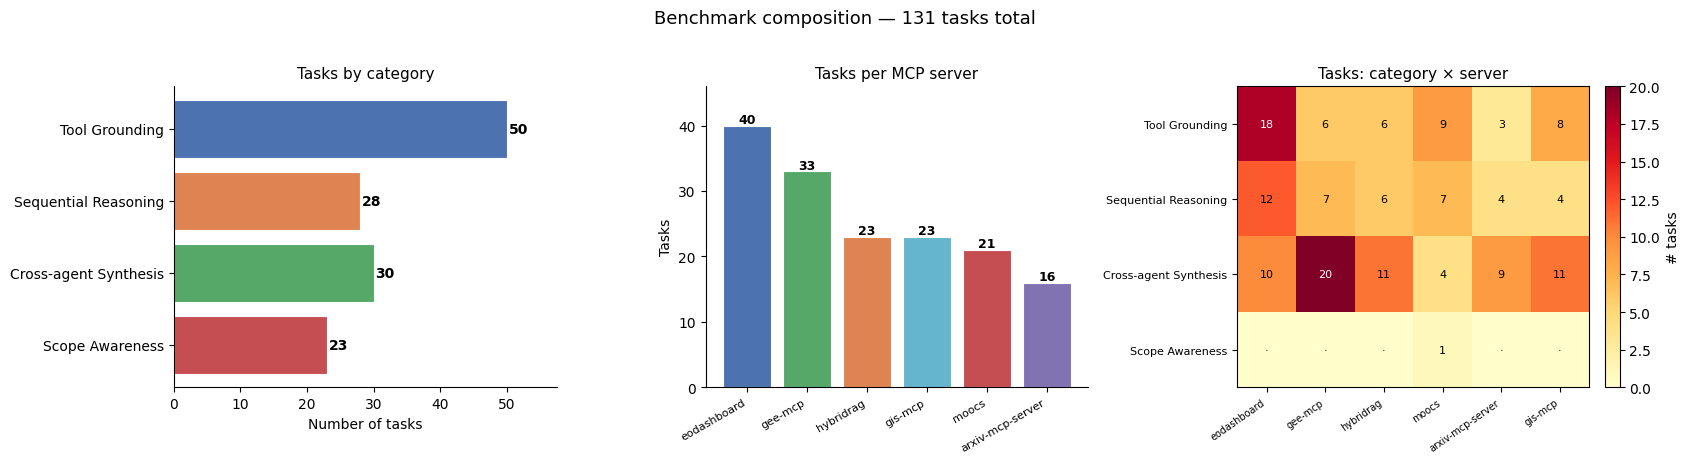

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# ── (A) Tasks by category ─────────────────────────────────────────────────
ax = axes[0]
cat_counts = df["category"].value_counts().reindex(CATEGORY_COLORS.keys()).dropna()
colors_a = [CATEGORY_COLORS.get(c, "#aaa") for c in cat_counts.index]
bars = ax.barh(cat_counts.index[::-1], cat_counts.values[::-1], color=colors_a[::-1],
               edgecolor="white", linewidth=0.8)
for bar, v in zip(bars, cat_counts.values[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height() / 2,
            str(v), va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("Number of tasks")
ax.set_title("Tasks by category", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, cat_counts.max() * 1.15)

# ── (B) Tasks by MCP server (exploded — task counted once per server) ─────
ax = axes[1]
server_rows = []
for _, row in df.iterrows():
    for srv in row["servers"]:
        server_rows.append({"server": srv, "task_ID": row["task_ID"]})
df_srv = pd.DataFrame(server_rows)
srv_counts = df_srv.groupby("server")["task_ID"].nunique().sort_values(ascending=False)
colors_b = [SERVER_COLORS.get(s, "#aaa") for s in srv_counts.index]
bars = ax.bar(srv_counts.index, srv_counts.values, color=colors_b,
              edgecolor="white", linewidth=0.8)
for bar, v in zip(bars, srv_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            str(v), ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("Tasks")
ax.set_title("Tasks per MCP server", fontsize=11)
ax.set_xticks(range(len(srv_counts)))
ax.set_xticklabels(srv_counts.index, rotation=30, ha="right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, srv_counts.max() * 1.15)

# ── (C) Heatmap: category × server ───────────────────────────────────────
ax = axes[2]
heat_rows = []
for _, row in df.iterrows():
    for srv in row["servers"]:
        heat_rows.append({"category": row["category"], "server": srv})
df_heat = pd.DataFrame(heat_rows)
mat = df_heat.groupby(["category", "server"]).size().unstack(fill_value=0)
cat_order = [c for c in CATEGORY_COLORS if c in mat.index]
srv_order  = [s for s in SERVER_COLORS  if s in mat.columns]
mat = mat.reindex(index=cat_order, columns=srv_order, fill_value=0)

im = ax.imshow(mat.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(srv_order)))
ax.set_xticklabels(srv_order, rotation=35, ha="right", fontsize=7)
ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order, fontsize=8)
ax.set_title("Tasks: category × server", fontsize=11)
for r in range(mat.shape[0]):
    for c in range(mat.shape[1]):
        v = mat.values[r, c]
        ax.text(c, r, str(v) if v else "·", ha="center", va="center",
                fontsize=8, color="white" if v > mat.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04, label="# tasks")

plt.suptitle(f"Benchmark composition — {len(df)} tasks total", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

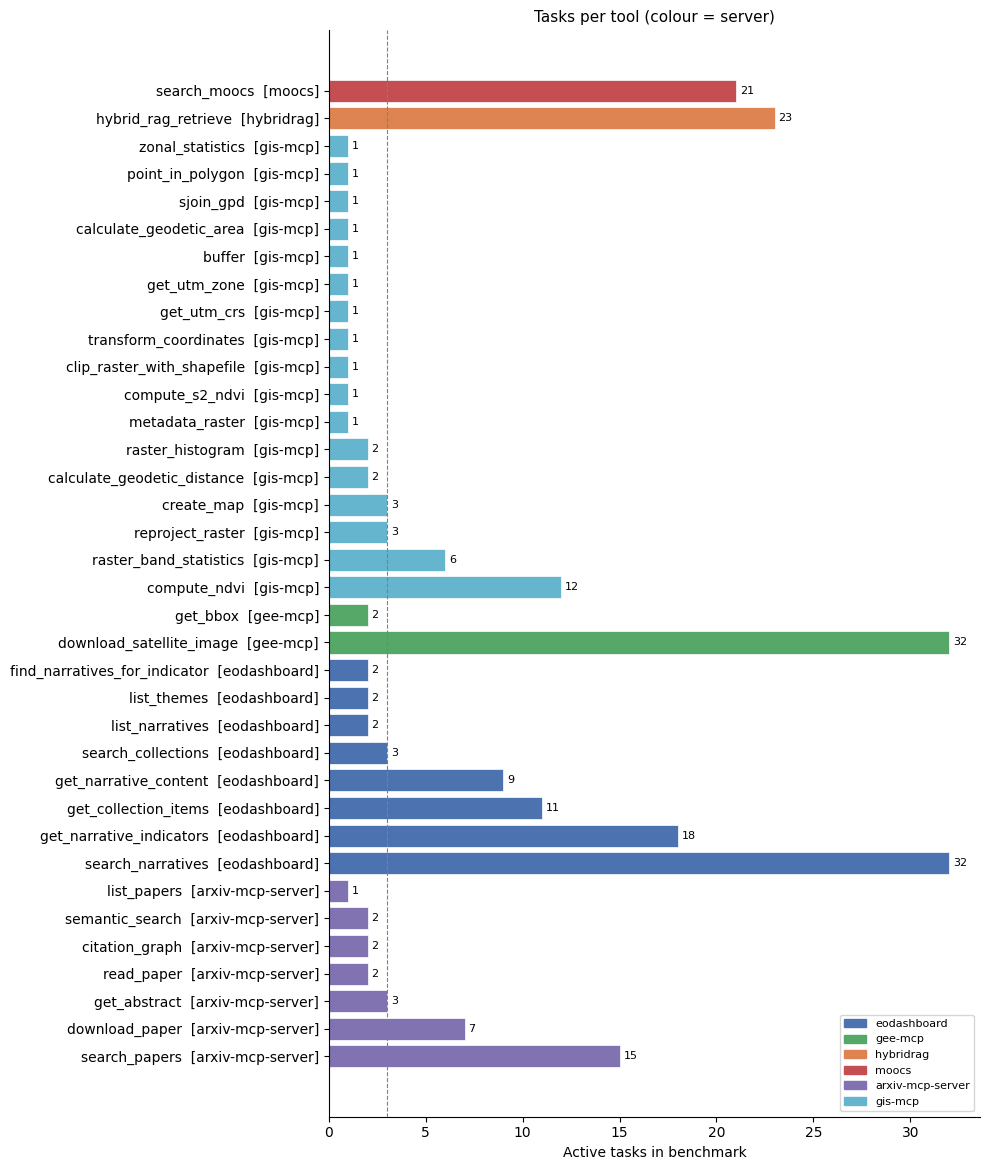

In [6]:
# Active tasks per tool (horizontal bar, grouped by server)
tool_data = [
    {"server": srv, "tool": t, "active_tasks": td["active_task_count"]}
    for srv, info in mc.items() for t, td in info["tools"].items()
]
df_tools = pd.DataFrame(tool_data).sort_values(["server", "active_tasks"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(10, max(5, len(df_tools) * 0.3 + 1)))
bar_colors = [SERVER_COLORS.get(r["server"], "#aaa") for _, r in df_tools.iterrows()]
labels = [f"{r['tool']}  [{r['server']}]" for _, r in df_tools.iterrows()]
bars = ax.barh(labels, df_tools["active_tasks"], color=bar_colors,
               edgecolor="white", linewidth=0.5)
for bar, v in zip(bars, df_tools["active_tasks"]):
    if v > 0:
        ax.text(v + 0.2, bar.get_y() + bar.get_height() / 2,
                str(v), va="center", fontsize=8)
ax.set_xlabel("Active tasks in benchmark")
ax.set_title("Tasks per tool (colour = server)", fontsize=11)
ax.axvline(3, color="grey", linestyle="--", linewidth=0.8, label="min coverage threshold (3)")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
# Legend patches for servers
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=c, label=s) for s, c in SERVER_COLORS.items() if s in df_tools["server"].values]
ax.legend(handles=patches, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

---
## 3 — Task Browser

**Overview table** — filterable by category, server, or text search.  
**Detail viewer** — inspect any task by ID or keyword.

In [ ]:
# ── Overview table ────────────────────────────────────────────────────────
# Filter controls: set any to None to show all
FILTER_CATEGORY = None          # e.g. "Tool Grounding"
FILTER_SERVER   = None          # e.g. "moocs"
FILTER_TEXT     = None          # e.g. "SAR"

# Build ordered call sequence per task (first reference solution only)
_task_calls = {}
for _t in tasks:
    _sols = _t.get("reference_solutions") or []
    _steps = _sols[0].get("steps", []) if _sols else []
    _fns = [s["function_name"] for s in _steps if s.get("function_name")]
    _task_calls[_t["task_ID"]] = "\n".join(f"{i+1}. {fn}" for i, fn in enumerate(_fns)) if _fns else "—"

view = df.copy()
if FILTER_CATEGORY:
    view = view[view["category"] == FILTER_CATEGORY]
if FILTER_SERVER:
    view = view[view["servers"].apply(lambda ss: FILTER_SERVER in ss)]
if FILTER_TEXT:
    view = view[view["task_text"].str.contains(FILTER_TEXT, case=False)]

display_df = view[["task_ID", "category", "servers", "task_text"]].copy()
display_df["servers"] = display_df["servers"].apply(lambda x: ", ".join(sorted(x)))
display_df["calls"]   = display_df["task_ID"].map(_task_calls)
display_df.columns    = ["ID", "Category", "Servers", "Task", "Calls"]

def _cat_color(val):
    c = CATEGORY_COLORS.get(val, "#eee")
    return f"background-color: {c}22; color: {c}; font-weight: bold"

styled_view = (
    display_df.style
    .map(_cat_color, subset=["Category"])
    .set_properties(subset=["Task"], **{
        "white-space": "normal",
        "word-wrap":   "break-word",
        "min-width":   "320px",
        "max-width":   "560px",
        "line-height": "1.5",
    })
    .set_properties(subset=["Calls"], **{
        "white-space":   "pre",
        "font-family":   "monospace",
        "font-size":     "10px",
        "line-height":   "1.7",
        "min-width":     "180px",
        "color":         "#2a5a8a",
    })
    .set_properties(subset=["ID"], **{
        "font-family": "monospace",
        "font-size":   "10px",
        "white-space": "nowrap",
    })
    .set_properties(subset=["Servers"], **{
        "font-size":   "10px",
        "white-space": "nowrap",
        "color":       "#555",
    })
    .set_properties(subset=["Category"], **{"white-space": "nowrap"})
    .set_caption(f"Showing {len(display_df)} / {len(df)} tasks")
    .set_table_styles([
        {"selector": "caption",
         "props": [("font-size", "12px"), ("font-weight", "bold"), ("text-align", "left"),
                   ("padding-bottom", "6px")]},
        {"selector": "td",
         "props": [("font-size", "11px"), ("vertical-align", "top"), ("padding", "5px 10px")]},
        {"selector": "th",
         "props": [("font-size", "11px"), ("white-space", "nowrap"), ("text-align", "left"),
                   ("padding", "5px 10px")]},
    ])
    .hide(axis="index")
)
display(styled_view)


In [8]:
# ── Task detail viewer ────────────────────────────────────────────────────
# Set INSPECT to a task_ID string, or a keyword (shows first match)
INSPECT = "TASK_260619_000006_300006"   # ← change this

task_map = {t["task_ID"]: t for t in tasks}

def show_task(query: str):
    # Exact ID match first
    if query in task_map:
        t = task_map[query]
    else:
        # Keyword search in task_text
        matches = [t for t in tasks if query.lower() in t["task_text"].lower()]
        if not matches:
            print(f"No task found matching {query!r}")
            return
        if len(matches) > 1:
            print(f"{len(matches)} matches — showing first. Others: {[m['task_ID'] for m in matches[1:6]]}")
        t = matches[0]

    label   = t.get("task_labels", ["—"])
    servers = sorted({TOOL_TO_SERVER.get(step["function_name"], "?") 
                      for sol in (t.get("reference_solutions") or [])
                      for step in sol.get("steps", [])})

    print(f"{'━'*70}")
    print(f"  {t['task_ID']}  |  {', '.join(label)}  |  servers: {', '.join(servers)}")
    print(f"{'━'*70}")
    print(f"\n  {t['task_text']}\n")
    if t.get("reference_solution_description"):
        print(f"  ↳ {t['reference_solution_description']}\n")

    for r_idx, sol in enumerate(t.get("reference_solutions") or []):
        header = f"  Reference {r_idx+1}:" if len(t["reference_solutions"]) > 1 else "  Reference:"
        if not sol.get("steps"):
            print(f"{header} (no tool calls — correct answer is to not call any tool)")
            continue
        for i, step in enumerate(sol["steps"]):
            args = ", ".join(f"{k}={v!r}" for k, v in step.get("arguments", {}).items())
            prefix = header if i == 0 else " " * len(header)
            print(f"{prefix}  {i+1}. {step['function_name']}({args})")
            if step.get("comment"):
                print(f"{' ' * len(header)}     # {step['comment']}")

    if t.get("generated_solution") is not None:
        gen = t["generated_solution"]
        print(f"\n  Generated solution:")
        for i, step in enumerate(gen.get("steps") or []):
            args = ", ".join(f"{k}={v!r}" for k, v in step.get("arguments", {}).items())
            print(f"    {i+1}. {step['function_name']}({args})")
        score = t.get("match_score_LLM")
        if score is not None:
            print(f"  LLM score: {score}")
    print()

show_task(INSPECT)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  TASK_260619_000006_300006  |  Cross-agent Synthesis  |  servers: gee-mcp, hybridrag, moocs
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Based on the ESA Science Strategy's priorities for glacier and cryosphere monitoring, find a MOOC lecture on ice sheet remote sensing, and download a Sentinel-2 image of the Aletsch Glacier (approximately 46.5°N, 8.0°E) for August 2023 at 30 m resolution.

  ↳ Agent retrieves Science Strategy cryosphere objectives from HybridRAG, searches the MOOC catalogue for an ice sheet remote sensing lecture, then downloads a Sentinel-2 image of the Aletsch Glacier via GEE.

  Reference:  1. hybrid_rag_retrieve(question='ESA Science Strategy cryosphere glacier ice sheet monitoring priorities')
                 # Retrieve Science Strategy content on cryosphere and glacier monitoring
              2. search_moocs(query='glacier ice sheet cryosphere remote sensing op

In [9]:
# ── Browse all tasks grouped by category ─────────────────────────────────
# Set BROWSE_CATEGORY to see all tasks in one category, or None for all
BROWSE_CATEGORY = "Tool Grounding"   # ← change this

CATEGORY_ORDER = ["Tool Grounding", "Sequential Reasoning", "Cross-agent Synthesis", "Scope Awareness"]
cats_to_show = [BROWSE_CATEGORY] if BROWSE_CATEGORY else CATEGORY_ORDER

for cat in cats_to_show:
    group = [t for t in tasks if cat in (t.get("task_labels") or [])]
    if not group:
        continue
    print(f"\n{'━'*72}")
    print(f"  {cat}  ({len(group)} tasks)")
    print(f"{'━'*72}")
    for t in group:
        fns = [step["function_name"]
               for sol in (t.get("reference_solutions") or [])
               for step in sol.get("steps", [])]
        srvs = sorted({TOOL_TO_SERVER.get(fn, "?") for fn in fns})
        print(f"\n  [{t['task_ID']}]  servers: {', '.join(srvs)}")
        print(f"  {t['task_text']}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Tool Grounding  (50 tasks)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  [TASK_260419_000001_100001]  servers: eodashboard
  List all available themes in the EO Dashboard.

  [TASK_260419_000002_100002]  servers: eodashboard
  Find narratives about wildfires and list the STAC collection codes they reference.

  [TASK_260419_000003_100003]  servers: eodashboard
  Retrieve the full content of any narrative about air quality.

  [TASK_260419_000006_100006]  servers: eodashboard
  Which narratives in the EO Dashboard reference the indicator collection EO:EEA:DAT:CLMS_CORINE_CLCPLUS_RASTER_2018_V1_1?

  [TASK_260419_000008_100008]  servers: eodashboard
  Find EO Dashboard narratives about greenhouse gas emissions and list the STAC collection codes they reference.

  [TASK_260419_000009_100009]  servers: eodashboard
  Find an EO Dashboard narrative about deforestation and retrieve its fu